## Problem set 3, Parts 2 and 3

Computational Macro (HWS 2026), University of Mannheim

*Team members: Federica Marrazza and Lorenzo Orsenigo

Part 1 derivations are in `derivations.pdf`. Parts 2 and 3 are solved below using the provided template.

### Packages and functions

In [1]:
# import Pkg; Pkg.activate(joinpath(@__DIR__, "..")); Pkg.instantiate()   # the course environment, if this notebook lies in Julia/Week_10/

In [1]:
using Plots
using Printf
using LinearAlgebra
using SparseArrays                                        # sparse matrices, for the policy chain
using Statistics
using QuantEcon                                           # rouwenhorst, as in week 5
using Distributions                                       # Normal and cdf, for the analytical distribution

In [2]:
Base.@kwdef struct EconomicParameters
    α::Float64 = 0.36         # capital share
    δ::Float64 = 0.1          # depreciation rate
    γ::Float64 = 4.0          # risk aversion: absolute with CARA utility, relative with CRRA utility
    φ::Float64 = 44 / 45      # survival probability: 45 periods of life on average
    ρ_e::Float64 = 0.9        # persistence of the income shock e
    σ_e::Float64 = 0.1        # unconditional standard deviation of e
    ρ_Z::Float64 = 0.9        # persistence of log TFP
    β::Float64 = 0.97         # discount factor, calibrated: solve_pranc (CARA) or calibrate_beta (CRRA)
    Zbar::Float64 = 1.0       # steady state TFP, calibrated by solve_pranc
end

Base.@kwdef struct NumericalParameters
    na::Int = 80              # asset grid points N_a
    ne::Int = 5               # income grid points N_e
    amin::Float64 = -30.0     # lowest asset grid point. CARA: no borrowing limit, the grid only has to reach where households go
    amax::Float64 = 100.0     # highest asset grid point
    crit_pol::Float64 = 1e-11 # the EGM stops when ln v moves by less: Reiter needs a tight steady state
    crit_dist::Float64 = 1e-13  # the distribution iteration stops when lam moves by less
    maxiter::Int = 100_000    # iteration cap, the safety net
end

struct Household
    name::String              # printed in the header line
    uprime::Function          # marginal utility u'(c), called as uprime(c, par)
    uprime_inv::Function      # its inverse: the c with u'(c) = m, called as uprime_inv(m, par)
    tolerance::Function       # -u'(c) / u''(c): dc = -tolerance * d ln u'(c), called as tolerance(c, par)
    endowment::Function       # labor endowment y(e) in income state e, with mean one: income is w y(e). Called as endowment(e, lam_e)
    borrowing_limit::Bool     # true: a' >= a_1 is a constraint of the household. false: a_1 is only the end of the grid
end

struct Grids
    a::Vector{Float64}        # asset grid, N_a
    e::Vector{Float64}        # grid of the income state e, N_e
    y::Vector{Float64}        # labor endowment y(e) on that grid, N_e: income is w y
    Pi::Matrix{Float64}       # transition matrix of e, N_e x N_e
    lam_e::Vector{Float64}    # stationary distribution of e, N_e
end

function change(par; kwargs...)
    # A copy of par or mpar with the named fields changed: change(par; σ_e = 0.3)
    fields = Dict{Symbol, Any}(f => getfield(par, f) for f in fieldnames(typeof(par)))
    for (key, val) in kwargs
        fields[key] = val
    end
    return typeof(par)(; fields...)
end

change (generic function with 1 method)

In [3]:
# CARA utility u(c) = -exp(-γ c) / γ: marginal utility, defined for every real c
uprime_cara(c, par) = exp.(-par.γ .* c)

# The c with u'(c) = m
uprime_inv_cara(m, par) = -log.(m) ./ par.γ

# -u'(c) / u''(c) = 1 / γ: the same at every level of consumption
tolerance_cara(c, par) = fill(1 / par.γ, size(c))

# Income is w (1 + e), with e an AR(1) in levels. lam_e, the stationary distribution of e, is not needed here
endowment_cara(e, lam_e) = 1 .+ e

CARA = Household("CARA", uprime_cara, uprime_inv_cara, tolerance_cara, endowment_cara, false)   # false: no borrowing limit

Household("CARA", Main.uprime_cara, Main.uprime_inv_cara, Main.tolerance_cara, Main.endowment_cara, false)

In [4]:
function prices(K, Z, par)
    # The firm's first-order conditions: the gross return R = 1 + r and the wage w
    R = par.α * Z * K^(par.α - 1) + 1 - par.δ
    w = (1 - par.α) * Z * K^par.α
    return R, w
end

function jacobian(f, x0; h = 1e-6)
    # The Jacobian of f at x0 by central differences: column j is df / dx_j (session 9)
    n, m = length(x0), length(f(x0))
    J = zeros(m, n)
    for j in 1:n
        e = zeros(n)
        e[j] = h
        J[:, j] = (f(x0 .+ e) .- f(x0 .- e)) ./ (2h)
    end
    return J
end

function linearize(F, xss, par)
    # The matrices A and B of the linear system A E x' = B x at the steady state xss (session 9)
    A = jacobian(x_next -> F(x_next, xss, par), xss)
    B = -jacobian(x -> F(xss, x, par), xss)
    return A, B
end

function solve_klein(A, B, n_states)
    # Klein (2000) in real arithmetic (session 10): G maps states into controls, H is the law of motion of the states
    Fs = schur(A, B)                                                          # A = Q S Z', B = Q T Z'
    stable = abs.(Fs.β) .< abs.(Fs.α)
    n_stable = sum(stable)
    if n_stable != n_states
        println("Klein: $n_stable stable eigenvalues for $n_states states")
    end
    ordschur!(Fs, stable)                                                     # the stable eigenvalues first
    Z11, Z21 = Fs.Z[1:n_states, 1:n_states], Fs.Z[n_states+1:end, 1:n_states]
    S11, T11 = Fs.S[1:n_states, 1:n_states], Fs.T[1:n_states, 1:n_states]
    G = Z21 / Z11                                                             # the controls on the states
    H = Z11 * (S11 \ T11) / Z11                                               # the law of motion of the states
    eigs = Fs.β ./ Fs.α                                                       # our λ_i = t_ii / s_ii
    return G, H, eigs
end

function impulse_response(G, H, n_states, T, shock)
    # The paths of states and controls for T periods after the shock vector hits the states in period 0 (session 9)
    s = zeros(T, n_states)
    s[1, :] = shock
    for t in 1:T-1
        s[t+1, :] = H * s[t, :]
    end
    return s, s * G'
end

impulse_response (generic function with 1 method)

In [5]:
function make_grids(par, mpar, hh)
    # Rouwenhorst for e (session 5): rouwenhorst wants the standard deviation of the innovation, σ_e sqrt(1 - ρ_e^2).
    # The asset grid is quadratically spaced around zero, where the newborns start: dense at a = 0, coarse at amin and amax.
    # With amin = 0 it is the grid of session 6
    mc = rouwenhorst(mpar.ne, par.ρ_e, par.σ_e * sqrt(1 - par.ρ_e^2))
    e = collect(mc.state_values)
    lam_e = vec(stationary_distributions(mc)[1])
    s = collect(range(-sqrt(-mpar.amin / mpar.amax), 1.0, length = mpar.na))
    a = mpar.amax .* s .* abs.(s)
    return Grids(a, e, hh.endowment(e, lam_e), Matrix(mc.p), lam_e)
end

function interp_extrap(x, xp, fp)
    # Linear interpolation of the points (xp, fp) at x, with linear extrapolation beyond the ends (session 9)
    out = similar(x)
    for (k, xq) in enumerate(x)
        i = clamp(searchsortedlast(xp, xq), 1, length(xp) - 1)               # the interval [xp[i], xp[i+1]] around xq
        w = (xq - xp[i]) / (xp[i+1] - xp[i])                                  # weight on the right end point, not clamped
        out[k] = (1 - w) * fp[i] + w * fp[i+1]
    end
    return out
end

interp_extrap (generic function with 1 method)

In [6]:
function lottery(a_prime, gri)
    # For every policy value a': the index l of the grid point just below it, and the weight w on the point above (session 6)
    na = length(gri.a)
    l = clamp.(searchsortedlast.(Ref(gri.a), a_prime), 1, na - 1)
    w = clamp.((a_prime .- gri.a[l]) ./ (gri.a[l .+ 1] .- gri.a[l]), 0.0, 1.0)
    return l, w
end

function transition_matrix(a_prime, gri)
    # The policy chain Q of session 6: Q[(i, m), (l, n)] = Pi[m, n] (1 - w_im) and Q[(i, m), (l + 1, n)] = Pi[m, n] w_im
    na, ne = length(gri.a), length(gri.e)
    idx = reshape(1:(na * ne), na, ne)                                        # idx[i, m] = i + (m - 1) N_a
    l, w = lottery(a_prime, gri)
    rows, cols, vals = Int[], Int[], Float64[]
    for m in 1:ne
        for n in 1:ne
            append!(rows, idx[:, m]); append!(cols, idx[l[:, m], n]); append!(vals, gri.Pi[m, n] .* (1 .- w[:, m]))
            append!(rows, idx[:, m]); append!(cols, idx[l[:, m] .+ 1, n]); append!(vals, gri.Pi[m, n] .* w[:, m])
        end
    end
    return sparse(rows, cols, vals, na * ne, na * ne)
end

function newborns(gri)
    # The newborns as a histogram of mass one: a = 0 by the lottery, e from its stationary distribution (session 10)
    l, w = lottery(zeros(1, 1), gri)
    lam_born = zeros(length(gri.a), length(gri.e))
    lam_born[l[1, 1], :] = (1 - w[1, 1]) .* gri.lam_e
    lam_born[l[1, 1] + 1, :] = w[1, 1] .* gri.lam_e
    return lam_born
end

function forward(lam, Q, lam_born, par)
    # One period of the histogram: survivors move along the policy chain, the dead are replaced by newborns (session 10)
    survivors = Q' * vec(lam)
    lam_new = par.φ .* survivors .+ (1 - par.φ) * sum(lam) .* vec(lam_born)
    return reshape(lam_new, size(lam))
end

function stationary_dist(Q, lam_born, par, mpar; lam0 = nothing)
    # Iterate forward until the histogram stops moving (session 6), from the newborns or from lam0
    lam = lam0 === nothing ? copy(lam_born) : lam0
    it = 0
    while it < mpar.maxiter
        it += 1
        lam_new = forward(lam, Q, lam_born, par)
        dist = maximum(abs.(lam_new .- lam))
        lam = lam_new
        dist < mpar.crit_dist && break
    end
    return lam, it
end

stationary_dist (generic function with 1 method)

### 2. Aggregate economy (PRANC with five equations)

$$
\begin{aligned}
K_{t+1} &= Z_t K_t^\alpha + (1 - \delta) K_t - C_t && \text{resource constraint} \\
\ln Z_{t+1} - \ln \bar Z &= \rho_Z (\ln Z_t - \ln \bar Z) && \text{TFP} \\
C_{t+1} &= C_t + \tfrac{1}{\gamma} \ln (\beta R_{t+1}) - \tfrac{1 - \varphi}{\varphi} \mu_{t+1} R_{t+1} K_{t+1}
          + \tfrac{\gamma}{2} (\mu_{t+1} + \nu_{t+1})^2 w_{t+1}^2 \sigma_\varepsilon^2 && \text{aggregate Euler equation} \\
\mu_t &= \frac{\mu_{t+1} R_{t+1}}{\varphi + \mu_{t+1} R_{t+1}} && \text{the MPC} \\
\nu_t &= \rho_e (1 - \mu_t) (\mu_{t+1} + \nu_{t+1}) \frac{w_{t+1}}{w_t} && \text{the loading on } e
\end{aligned}
$$

with $\sigma_\varepsilon^2 = \sigma_e^2 (1 - \rho_e^2)$.

In [7]:
function pranc_steady_state(par; r = 0.04, Y = 1.0)
    # The steady state of the aggregate economy with the rate r and output Y: the firm gives K, Zbar, w,
    # the household's coefficients μ and ν, and the aggregate Euler equation with C' = C gives β
    # Every call calibrates β and Zbar so that the steady state has r = 4 percent and Y = 1
    R = 1 + r
    K = par.α * Y / (r + par.δ)                                               # the firm: r = α Y / K - δ
    Zbar = Y / K^par.α
    w = (1 - par.α) * Y
    C = Y - par.δ * K                                                         # the resource constraint, K' = K
    μ = 1 - par.φ / R                                                         # the MPC out of cash on hand
    ν = par.ρ_e * par.φ * μ / (R - par.ρ_e * par.φ)                           # the extra response to a persistent e
    sig_eps2 = par.σ_e^2 * (1 - par.ρ_e^2)                                    # variance of the innovation to e
    newborn = (1 - par.φ) / par.φ * μ * R * K                                 # the term of the newborns
    precaution = par.γ / 2 * (μ + ν)^2 * w^2 * sig_eps2                       # the precautionary term
    β = exp(par.γ * (newborn - precaution)) / R
    return (K = K, C = C, Z = Zbar, R = R, w = w, μ = μ, ν = ν, β = β, Y = Y, newborn = newborn, precaution = precaution)
end

function F_pranc(x_next, x, par)
    # The five equations as residuals. x = (ln K, ln Z, ln C, ln μ, ln ν) today, x_next tomorrow
    K, Z, C, μ, ν = exp.(x)
    K1, Z1, C1, μ1, ν1 = exp.(x_next)
    R, w = prices(K, Z, par)
    R1, w1 = prices(K1, Z1, par)
    sig_eps2 = par.σ_e^2 * (1 - par.ρ_e^2)
    return [
        log(K1) - log(Z * K^par.α + (1 - par.δ) * K - C),                     # resource constraint
        log(Z1 / par.Zbar) - par.ρ_Z * log(Z / par.Zbar),                     # TFP, without the shock
        C1 - C - log(par.β * R1) / par.γ +                                    # aggregate Euler equation:
            (1 - par.φ) / par.φ * μ1 * R1 * K1 -                              #   the newborns own none of K'
            par.γ / 2 * (μ1 + ν1)^2 * w1^2 * sig_eps2,                        #   precaution
        log(μ) - log(μ1 * R1 / (par.φ + μ1 * R1)),                            # the MPC
        log(ν) - log(par.ρ_e * (1 - μ) * (μ1 + ν1) * w1 / w),                 # the loading on e
    ]
end

F_pranc (generic function with 1 method)

In [8]:
function solve_pranc(par; T = 60, shock = 0.01, verbose = true)
    # The aggregate economy from start to end: calibration, linearization, Klein, impulse responses to a TFP shock
    ss = pranc_steady_state(par)
    par = change(par; β = ss.β, Zbar = ss.Z)                                  # the calibrated economy
    xss = log.([ss.K, ss.Z, ss.C, ss.μ, ss.ν])
    A, B = linearize(F_pranc, xss, par)
    G, H, eigs = solve_klein(A, B, 2)
    s, c = impulse_response(G, H, 2, T, [0.0, shock])
    res = (name = "PRANC", par = par, ss = ss, G = G, H = H, eigs = eigs, K = s[:, 1], Z = s[:, 2], Y = s[:, 2] .+ par.α .* s[:, 1],
           C = c[:, 1], μ = c[:, 2], ν = c[:, 3])
    if verbose
        println("PRANC with ", par)
        @printf("  steady state: K = %.4f, C = %.4f, μ = %.5f, ν = %.5f, β = %.5f, β R = %.5f\n", ss.K, ss.C, ss.μ, ss.ν, ss.β, ss.β * ss.R)
        @printf("  largest residual at the steady state: %.1e, eigenvalues: %s\n", maximum(abs.(F_pranc(xss, xss, par))),
                string(round.(sort(abs.(eigs)), digits = 4)))
        @printf("  C on impact %.3f percent, K peaks at %.3f percent in period %d\n", 100 * res.C[1], 100 * maximum(res.K), argmax(res.K) - 1)
    end
    return res
end

solve_pranc (generic function with 1 method)

### 4. The heterogeneous agent economy: Reiter's method

The functions of session 10, with one change: the household is the argument `hh`. Read `egm_step` with the two
models in mind: the Euler equation is inverted with `hh.uprime_inv`, the envelope condition uses `hh.uprime`,
income is the wage times the labor endowment `gri.y`, and one line imposes the borrowing limit if the household
has one.

`solve_reiter(par, mpar, hh)` does everything for a calibrated `par`: the grids, the steady state by bisection
on $r$, the system $\mathbf{F}$ with $2 N_a N_e + 1$ variables, its linearization, Klein, and the impulse
responses to a one percent TFP shock. Its result `res` is a named tuple: `res.K`, `res.C`, `res.Y`,
`res.Z` are the paths in log deviations, `res.agg` the steady state on the grid (`agg.c`, `agg.a_prime`,
`agg.lam`, `agg.K`, ...), `res.gri` the grids, `res.r_star`, `res.eigs`, `res.resid`, and the run
times `res.t_ss`, `res.t_jac`, `res.t_qz`.

In [9]:
function egm_step(lnv_next, R, w, par, gri, hh)
    # One step of the EGM on marginal values (session 10): from ln v' on the grid (a'_l, e_n) to today's savings policy
    # a_prime, consumption c, and ln v, all N_a x N_e, at today's prices R and w
    Ev = par.φ .* exp.(lnv_next) * gri.Pi'                                    # E[v' | e_m] at every a'_l, the dead need no assets
    ctilde = hh.uprime_inv(par.β .* Ev, par)                                  # (a) the Euler equation u'(c) = β φ E[v'], solved for c
    xtilde = ctilde .+ gri.a                                                  # (b) the cash on hand at which a'_l is chosen
    x = R / par.φ .* gri.a .+ w .* gri.y'                              # cash on hand on the grid
    a_prime = similar(x)
    for m in 1:length(gri.e)                                                  # (c) back to the grid, one income state at a time
        a_prime[:, m] = interp_extrap(x[:, m], xtilde[:, m], gri.a)
    end
    if hh.borrowing_limit
        a_prime = max.(a_prime, gri.a[1])                                     # the borrowing limit a' >= a_1
    end
    c = x .- a_prime
    lnv = log(R / par.φ) .+ log.(hh.uprime(c, par))                           # (d) the envelope condition v = (R / φ) u'(c), in logs
    return a_prime, c, lnv
end

function solve_household(R, w, par, mpar, gri, hh; lnv0 = nothing)
    # Iterate egm_step at constant prices until ln v stops moving (session 5). The guess: keep assets constant, a' = a
    if lnv0 === nothing
        x = R / par.φ .* gri.a .+ w .* gri.y'
        lnv0 = log(R / par.φ) .+ log.(hh.uprime(x .- gri.a, par))
    end
    lnv, a_prime, c, it = lnv0, similar(lnv0), similar(lnv0), 0
    while it < mpar.maxiter
        it += 1
        a_prime, c, lnv_new = egm_step(lnv, R, w, par, gri, hh)
        dist = maximum(abs.(lnv_new .- lnv))
        lnv = lnv_new
        dist < mpar.crit_pol && break
    end
    return a_prime, c, lnv, it
end

solve_household (generic function with 1 method)

In [10]:
mutable struct Aggregates
    S::Float64                # asset supply: mean savings of the households
    K::Float64                # capital demand of the firm
    R::Float64                # gross return 1 + r
    w::Float64                # wage
    a_prime::Matrix{Float64}  # savings policy a'(a, e), N_a x N_e
    c::Matrix{Float64}        # consumption policy
    lnv::Matrix{Float64}      # log marginal values
    lam::Matrix{Float64}      # stationary histogram
end

function aggregate(r, par, mpar, gri, hh, lam_born; warm = nothing)
    # The household block at the rate r (sessions 7 and 8): prices, policy, histogram, supply S(r) and demand K(r)
    K = (par.α * par.Zbar / (r + par.δ))^(1 / (1 - par.α))                    # the firm's capital demand at r
    R, w = prices(K, par.Zbar, par)
    a_prime, c, lnv, _ = solve_household(R, w, par, mpar, gri, hh; lnv0 = warm === nothing ? nothing : warm.lnv)
    lam, _ = stationary_dist(transition_matrix(a_prime, gri), lam_born, par, mpar; lam0 = warm === nothing ? nothing : warm.lam)
    return Aggregates(sum(lam .* a_prime), K, R, w, a_prime, c, lnv, lam)
end

function equilibrium(par, mpar, gri, hh, lam_born, lo, hi; tol = 1e-12)
    # Bisection on the excess supply S(r) - K(r), which increases in r, with warm starts (session 8)
    warm, k = nothing, 0
    while hi - lo > tol
        mid = (lo + hi) / 2
        warm = aggregate(mid, par, mpar, gri, hh, lam_born; warm = warm)
        lo, hi = warm.S < warm.K ? (mid, hi) : (lo, mid)
        k += 1
    end
    r = (lo + hi) / 2
    return r, aggregate(r, par, mpar, gri, hh, lam_born; warm = warm), k
end

equilibrium (generic function with 1 method)

In [11]:
function unpack(x, gri)
    # The vector x as its four blocks: the histogram (with its last bin restored), K, Z, and ln v (session 10)
    na, ne = length(gri.a), length(gri.e)
    N = na * ne
    lam = reshape([x[1:N-1]; 1 - sum(x[1:N-1])], na, ne)                      # the last bin: the histogram sums to one
    lnv = reshape(x[N+2:end], na, ne)
    return lam, exp(x[N]), exp(x[N+1]), lnv
end

function pack(lam, K, Z, lnv)
    # The inverse of unpack: the four blocks as one vector, the histogram without its last bin
    N = length(lam)
    return [vec(lam)[1:N-1]; log(K); log(Z); vec(lnv)]
end

function F_reiter(x_next, x, par, gri, hh, lam_born)
    # Reiter's system (session 10): zero along an equilibrium path without shocks
    lam, K, Z, lnv = unpack(x, gri)                                           # today
    lam1, K1, Z1, lnv1 = unpack(x_next, gri)                                  # tomorrow
    R, w = prices(K, Z, par)                                                  # today's prices
    a_prime, c, lnv_egm = egm_step(lnv1, R, w, par, gri, hh)                  # one EGM step from tomorrow's v
    lam_fwd = forward(lam, transition_matrix(a_prime, gri), lam_born, par)    # one step of Young's method
    N = length(lam)
    return [vec(lam1 .- lam_fwd)[1:N-1];                                      # Young: all bins but the last
            log(K1) - log(sum(lam .* a_prime));                               # asset market: K' is the mean of today's savings
            log(Z1 / par.Zbar) - par.ρ_Z * log(Z / par.Zbar);                 # TFP, without the shock
            vec(lnv .- lnv_egm)]                                              # EGM: today's marginal values
end

function consumption_from_households(s_h, c_h, agg, par, gri, hh)
    # C_t = sum lam_t c_t, linearized: d lam times c plus lam times dc. The change of the policy is read off the
    # marginal values: ln v = ln(R / φ) + ln u'(c), so dc = tolerance(c) (d ln R - d ln v)
    na, ne = length(gri.a), length(gri.e)
    N = na * ne
    dlnR = (agg.R - 1 + par.δ) / agg.R .* (s_h[:, N+1] .+ (par.α - 1) .* s_h[:, N])   # d ln R from d ln Z and d ln K
    dC = zeros(size(s_h, 1))
    for t in 1:size(s_h, 1)
        dlam = reshape([s_h[t, 1:N-1]; -sum(s_h[t, 1:N-1])], na, ne)          # the change of the histogram, sums to zero
        dlnv = reshape(c_h[t, :], na, ne)                                     # the change of ln v on the grid
        dc = hh.tolerance(agg.c, par) .* (dlnR[t] .- dlnv)
        dC[t] = sum(dlam .* agg.c) + sum(agg.lam .* dc)
    end
    return dC ./ sum(agg.lam .* agg.c)
end

consumption_from_households (generic function with 1 method)

In [12]:
function solve_reiter(par, mpar, hh; T = 60, shock = 0.01, r_lo = 0.03, r_hi = 0.05, verbose = true)
    # The heterogeneous agent economy from start to end: grids, steady state, Reiter's system, Klein, impulse responses
    gri = make_grids(par, mpar, hh)
    lam_born = newborns(gri)
    t0 = time()
    r_star, agg, _ = equilibrium(par, mpar, gri, hh, lam_born, r_lo, r_hi)    # the steady state on the grid
    t_ss = time() - t0
    N = mpar.na * mpar.ne
    n_states = N + 1                                                          # the histogram without its last bin, K, and Z
    xss = pack(agg.lam, agg.K, par.Zbar, agg.lnv)
    F = (x_next, x, p) -> F_reiter(x_next, x, p, gri, hh, lam_born)           # F with the grids and the household filled in
    resid = maximum(abs.(F(xss, xss, par)))
    t0 = time()
    A, B = linearize(F, xss, par)
    t_jac = time() - t0
    t0 = time()
    G, H, eigs = solve_klein(A, B, n_states)
    t_qz = time() - t0
    s0 = zeros(n_states)
    s0[N+1] = shock                                                           # log TFP is the last state
    s_h, c_h = impulse_response(G, H, n_states, T, s0)
    K_h, Z_h = s_h[:, N], s_h[:, N+1]                                         # log deviations of K and Z
    Y_h = Z_h .+ par.α .* K_h
    C_h = consumption_from_households(s_h, c_h, agg, par, gri, hh)            # consumption summed over the households
    C, Y = sum(agg.lam .* agg.c), par.Zbar * agg.K^par.α
    C_rc = (Y .* Y_h[1:end-1] .+ (1 - par.δ) * agg.K .* K_h[1:end-1] .- agg.K .* K_h[2:end]) ./ C   # ... and from the resource constraint
    at_limit = sum(agg.lam .* (agg.a_prime .<= gri.a[1] + 1e-10))             # share of households with a' at the lowest grid point
    res = (name = "Reiter ($(hh.name))", par = par, mpar = mpar, hh = hh, gri = gri, lam_born = lam_born, r_star = r_star, agg = agg,
           G = G, H = H, eigs = eigs, K = K_h, Z = Z_h, Y = Y_h, C = C_h, resid = resid, walras = maximum(abs.(C_h[1:end-1] .- C_rc)),
           at_limit = at_limit, top = sum(agg.lam[end, :]), bottom = sum(agg.lam[1, :]), t_ss = t_ss, t_jac = t_jac, t_qz = t_qz)
    if verbose
        println("Reiter ($(hh.name)) with ", par, ", N_a = $(mpar.na), N_e = $(mpar.ne), grid = [$(mpar.amin), $(mpar.amax)]")
        @printf("  steady state: r* = %.5f percent, K = %.5f, C = %.5f, mass at a_1: %.1e, at a_N: %.1e, households with a' = a_1: %.2f percent (%.1f s)\n",
                100 * r_star, agg.K, C, res.bottom, res.top, 100 * at_limit, t_ss)
        @printf("  Reiter: %d variables, largest residual at the steady state %.1e, %d stable eigenvalues for %d states, Jacobians %.1f s, Klein %.1f s\n",
                length(xss), resid, sum(abs.(eigs) .< 1), n_states, t_jac, t_qz)
        @printf("  C on impact %.3f percent, K peaks at %.3f percent in period %d, goods market gap %.1e\n",
                100 * C_h[1], 100 * maximum(K_h), argmax(K_h) - 1, res.walras)
    end
    return res
end

solve_reiter (generic function with 1 method)

### 5. Reporting

| Tool | What it does |
| --- | --- |
| `compare(results)` | one line per result: consumption on impact, the peak of capital and its period |
| `plot_irfs(results)` | capital, consumption, and output after the shock, one line per result |
| `plot_cdf(results, ss)` | CARA only: the distribution of cash on hand on the grid, one line per result, against the analytical CDF of session 10 |

`results` is a vector of pairs `[label => res, ...]` of results of `solve_pranc`, `solve_reiter`, or `solve_rbc`.

In [13]:
function compare(results)
    # One line per result: the two numbers we compare across economies
    @printf("%-36s%12s%12s%8s\n", "", "C on impact", "K at peak", "period")
    for (label, res) in results
        @printf("%-36s%12.3f%12.3f%8d\n", label, 100 * res.C[1], 100 * maximum(res.K), argmax(res.K) - 1)
    end
end

function plot_irfs(results)
    # Capital, consumption, and output in percent deviation from the steady state, one line per result
    styles = [:solid, :dash, :dot, :dashdot]
    panels = []
    for (key, name) in ((:K, "capital"), (:C, "consumption"), (:Y, "output"))
        p = plot(title = name, titlefontsize = 10, xlabel = "periods after the shock", legend = key == :K ? :topright : false)
        for (k, (label, res)) in enumerate(results)
            y = getproperty(res, key)
            plot!(p, 0:length(y)-1, 100 .* y, lw = 2, ls = styles[mod1(k, 4)], label = label)
        end
        hline!(p, [0], color = :black, lw = 0.5, label = "")
        push!(panels, p)
    end
    plot!(panels[1], ylabel = "percent deviation", legendfontsize = 7)
    return plot(panels..., layout = (1, 3), size = (950, 300), link = :y, bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

plot_irfs (generic function with 1 method)

In [14]:
function analytical_cdf(x, par, ss; tol = 1e-13)
    # The stationary CDF of cash on hand in the CARA economy (session 10): a mixture over ages k of normals N(m_k, V_k)
    Rφ, w, μ, ν = ss.R / par.φ, ss.w, ss.μ, ss.ν
    f = ss.C - μ * (ss.R * ss.K + w)                                          # the intercept of the policy
    κ = par.ρ_e - Rφ * ν                                                      # how much of e stays in x
    sig_eps2 = par.σ_e^2 * (1 - par.ρ_e^2)
    m, V, Cov = w, w^2 * par.σ_e^2, w * par.σ_e^2                             # age 0: x = w (1 + e)
    d = w - Rφ * f                                                            # the mean grows by d per year of age
    F, weight = zeros(length(x)), 1 - par.φ
    while weight > tol
        F .+= weight .* cdf.(Normal(), (x .- m) ./ sqrt(V))
        V, Cov = V + w^2 * κ^2 * par.σ_e^2 + w^2 * sig_eps2 + 2 * w * κ * Cov, par.ρ_e * Cov + w * (par.ρ_e * κ * par.σ_e^2 + sig_eps2)
        m += d
        weight *= par.φ
    end
    return F
end

function plot_cdf(results, ss)
    # CARA only: the CDF of cash on hand on the grid, one line per result, against the analytical one
    p = plot(xlabel = "cash on hand x", ylabel = "CDF", xlims = (-2, 15), legend = :bottomright, size = (600, 300))
    for (label, res) in results
        agg, gri, par = res.agg, res.gri, res.par
        x = agg.R / par.φ .* gri.a .+ agg.w .* gri.y'
        order = sortperm(vec(x))
        plot!(p, vec(x)[order], cumsum(vec(agg.lam)[order]), seriestype = :steppost, lw = 1.5, label = label)
    end
    xx = collect(range(-2.0, 15.0, length = 400))
    plot!(p, xx, analytical_cdf(xx, results[1].second.par, ss), color = :black, ls = :dash, lw = 1, label = "analytical")
    return p
end

plot_cdf (generic function with 1 method)

### Part 2: the CARA economy

#### Question 2.1: Five equations against 801 variables

In [17]:
pranc = solve_pranc(EconomicParameters())
par = pranc.par                                                               # the calibrated economy
ss = pranc.ss;

PRANC with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289)
  steady state: K = 2.5714, C = 0.7429, μ = 0.05983, ν = 0.32906, β = 0.97471, β R = 1.01370
  largest residual at the steady state: 2.2e-17, eigenvalues: [0.9, 0.9273, 1.0511, 1.1324, 1.1844]
  C on impact 0.552 percent, K peaks at 1.026 percent in period 11


In [18]:
mpar = NumericalParameters()
reiter = solve_reiter(par, mpar, CARA);

Reiter (CARA) with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289), N_a = 80, N_e = 5, grid = [-30.0, 100.0]
  steady state: r* = 4.00012 percent, K = 2.57139, C = 0.74286, mass at a_1: 5.0e-28, at a_N: 4.9e-12, households with a' = a_1: 0.00 percent (1.3 s)
  Reiter: 801 variables, largest residual at the steady state 3.3e-10, 401 stable eigenvalues for 401 states, Jacobians 1.3 s, Klein 1.5 s
  C on impact 0.552 percent, K peaks at 1.026 percent in period 11, goods market gap 8.7e-11


**2.1 (a):** Report $r$, $K$, $C$, and $\beta$ in steady state for both solvers.

In [19]:
@printf("%-13s %12s %12s %12s %12s\n", "model", "r (%)", "K", "C", "β")
@printf("%-13s %12.5f %12.5f %12.5f %12.6f\n", "PRANC", 4.0, ss.K, ss.C, pranc.par.β)
@printf("%-13s %12.5f %12.5f %12.5f %12.6f\n", "Reiter", 100 * reiter.r_star,
        reiter.agg.K, sum(reiter.agg.lam .* reiter.agg.c), reiter.par.β)

model                r (%)            K            C            β
PRANC              4.00000      2.57143      0.74286     0.974708
Reiter             4.00012      2.57139      0.74286     0.974708


**2.1 (b):** Impulse responses of capital, consumption, and output after a 1% TFP shock.

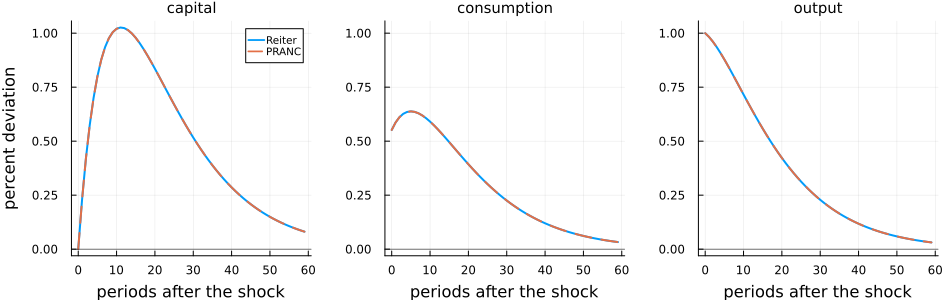

In [20]:
plot_irfs(["Reiter" => reiter, "PRANC" => pranc])

**2.1 (c):** Stationary CDF of cash on hand on the grid and the analytical distribution.

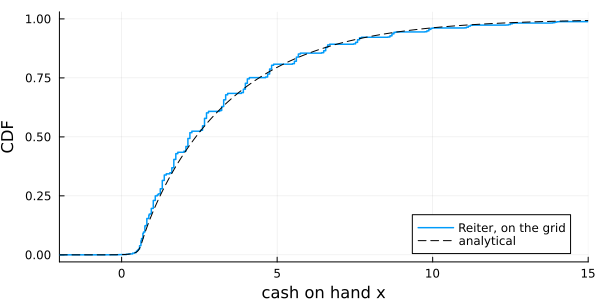

In [20]:
plot_cdf(["Reiter, on the grid" => reiter], ss)

**2.1 (d):** Assess the approximation of the PRANC dynamics by the Reiter solution.

In [21]:
@printf("maximum absolute Reiter–PRANC gap (percentage points, 60 periods):\n")
for (name, h, p) in (("capital", reiter.K, pranc.K), ("consumption", reiter.C, pranc.C),
                     ("output", reiter.Y, pranc.Y))
    @printf("  %-12s %.6f\n", name, 100 * maximum(abs.(h .- p)))
end

maximum absolute Reiter–PRANC gap (percentage points, 60 periods):
  capital      0.000006
  consumption  0.000005
  output       0.000002


The grid solution approximates very closely the five-equation benchmark, as the IRFs coincide and differences across periods are of order of magnitude 10^(-6) at most (due to the discretization error of assets and income).

#### Question 2.2: Varying the grids

**2.2 (a):** Solve for $N_a\in\{40,80,120\}$; tabulate the number of variables, $r^*$, and the three run times, then plot the CDFs and impulse responses.

Reiter (CARA) with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289), N_a = 40, N_e = 5, grid = [-30.0, 100.0]
  steady state: r* = 4.00012 percent, K = 2.57139, C = 0.74286, mass at a_1: 4.2e-18, at a_N: 7.9e-10, households with a' = a_1: 0.00 percent (0.1 s)
  Reiter: 401 variables, largest residual at the steady state 9.4e-12, 201 stable eigenvalues for 201 states, Jacobians 0.1 s, Klein 0.3 s
  C on impact 0.552 percent, K peaks at 1.026 percent in period 11, goods market gap 1.0e-10
Reiter (CARA) with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289), N_a = 120, N_e = 5, grid = [-30.0, 100.0]
  steady state: r* = 4.00012 percent, K = 2.57139, C = 0.74286, mass at a_1: 1.3e-35, at a_N: 3.9e-13, households with a' = a_1: 0.00 percent (0.3 s)
  Reiter: 1201 variables, largest residual at the steady state 3.8e-10, 601 stable eigenvalues for 601 states, Jacobians 2.0 

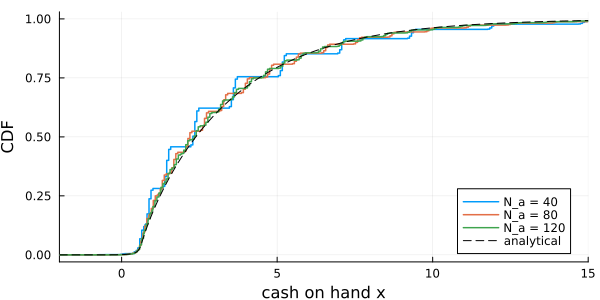

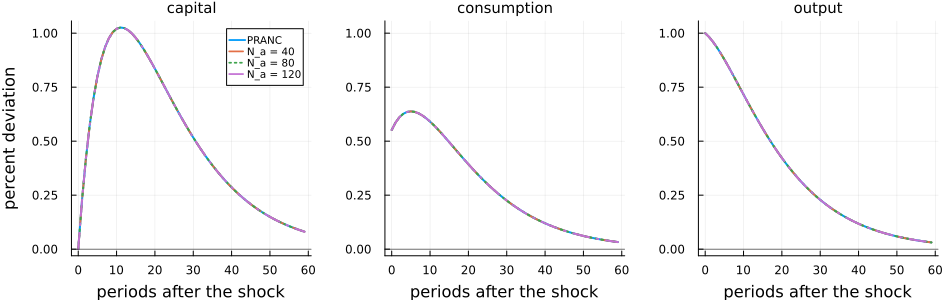

In [21]:
# 2.2 (a): asset-grid comparisons (reuse the N_a = 80 baseline)
asset_results = Dict{Int,Any}(
    40 => solve_reiter(par, change(mpar; na = 40), CARA),
    80 => reiter,
    120 => solve_reiter(par, change(mpar; na = 120), CARA),
)
@printf("%-5s %8s %12s %12s %12s %12s\n", "N_a", "n", "r* (%)", "SS (s)", "Jac (s)", "Klein (s)")
for na in (40, 80, 120)
    res = asset_results[na]
    @printf("%-5d %8d %12.6f %12.3f %12.3f %12.3f\n", na, 2 * na * mpar.ne + 1,
            100 * res.r_star, res.t_ss, res.t_jac, res.t_qz)
end

display(plot_cdf(["N_a = $na" => asset_results[na] for na in (40, 80, 120)], ss))
display(plot_irfs(["PRANC" => pranc;
                   ["N_a = $na" => asset_results[na] for na in (40, 80, 120)]]))

**2.2 (b):** The number of variables in the linear system, computational run times, and discretization error depend on Na. As a result, the approximated CDF of cash on hand and the IRFs to a productivity shock should also depend on Na. However, we observe that while the number of variables and the Jacobian and Klein run times increase substantially with Na, and the CDF of cash on hand becomes more accurate with a finer grid, both r* and the IRFs remain unchanged even with the coarsest asset grid (Na=120).

**2.2 (c):** As number of variables increases from 401 to 1201, the Jacobian computation's runtime exhibits roughly quadratic scaling (as number of variables increase threefold, Jacobian runtime increases by 3^2), whereas Klein's method scales closer to cubically. 

The quadratic scaling for the Jacobian computation is due to the fact that in this step the derivatives of the n=2*Na*Ne+1 equilibrium equations are computed with respect to the n variables of the linear system. And, since tripling Na roughly triples both the number of variables and the number of equilibrium conditions, the Jacobian matrices contain roughly n^2 derivatives, consistent with the quadratic scaling of the runtime.

Klein's method is even more computationally expensive as Na increases, since it involves a QZ decomposition of the n X n matrices obtained in the Jacobian step.

**2.2 (d):** Keeping $N_a=80$, vary $N_e\in\{3,5,9\}$ and tabulate $r^*$.

In [22]:
# 2.2 (d): solve each income-grid specification with Reiter's method
income_results = Dict{Int,Any}(
    3 => solve_reiter(par, change(mpar; ne = 3), CARA),
    5 => reiter,
    9 => solve_reiter(par, change(mpar; ne = 9), CARA),
)
@printf("%-8s %12s\n", "N_e", "r* (%)")
for ne in (3, 5, 9)
    @printf("%-8d %12.6f\n", ne, 100 * income_results[ne].r_star)
end

Reiter (CARA) with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289), N_a = 80, N_e = 3, grid = [-30.0, 100.0]
  steady state: r* = 4.00024 percent, K = 2.57136, C = 0.74285, mass at a_1: 0.0e+00, at a_N: 4.5e-12, households with a' = a_1: 0.00 percent (0.3 s)
  Reiter: 481 variables, largest residual at the steady state 6.0e-11, 241 stable eigenvalues for 241 states, Jacobians 0.1 s, Klein 0.5 s
  C on impact 0.552 percent, K peaks at 1.026 percent in period 11, goods market gap 1.2e-10
Reiter (CARA) with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9747084942650038, 0.7117659246173289), N_a = 80, N_e = 9, grid = [-30.0, 100.0]
  steady state: r* = 4.00006 percent, K = 2.57141, C = 0.74286, mass at a_1: 3.3e-25, at a_N: 4.8e-12, households with a' = a_1: 0.00 percent (0.4 s)
  Reiter: 1441 variables, largest residual at the steady state 5.2e-11, 721 stable eigenvalues for 721 states, Jacobians 3.9 s

**2.2 (e):** The precautionary term $P_{t+1}$ in equation (4) is responsible, in fact, by changing the income grid, we change the discrete approximation of income risk and hence precautionary saving, shifting the grid equilibrium rate $r^*$.

#### Question 2.3: Income risk

**2.3 (a):** Recalibrate $\beta$ for $\sigma_e\in\{0,0.1,0.3\}$ and plot their impulse responses.

PRANC with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.0, 0.9, 0.9756266869591473, 0.7117659246173289)
  steady state: K = 2.5714, C = 0.7429, μ = 0.05983, ν = 0.32906, β = 0.97563, β R = 1.01465
  largest residual at the steady state: 2.8e-17, eigenvalues: [0.9, 0.9273, 1.0497, 1.1364, 1.1818]
  C on impact 0.553 percent, K peaks at 1.025 percent in period 11
PRANC with EconomicParameters(0.36, 0.1, 4.0, 0.9777777777777777, 0.9, 0.3, 0.9, 0.9673939935254383, 0.7117659246173289)
  steady state: K = 2.5714, C = 0.7429, μ = 0.05983, ν = 0.32906, β = 0.96739, β R = 1.00609
  largest residual at the steady state: 2.0e-17, eigenvalues: [0.9, 0.9272, 1.0674, 1.1022, 1.1984]
  C on impact 0.541 percent, K peaks at 1.040 percent in period 11
σ_e                     β
0.0            0.97562669
0.1            0.97470849
0.3            0.96739399


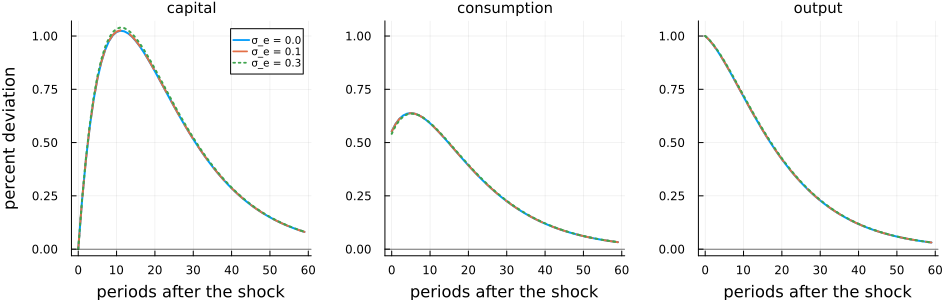

In [23]:
# 2.3 (a): recalibrate β for each level of income risk
risk_pranc = Dict{Float64,Any}(
    0.0 => solve_pranc(EconomicParameters(σ_e = 0.0)),
    0.1 => pranc,
    0.3 => solve_pranc(EconomicParameters(σ_e = 0.3)),
)
@printf("%-10s %14s\n", "σ_e", "β")
for risk in (0.0, 0.1, 0.3)
    @printf("%-10.1f %14.8f\n", risk, risk_pranc[risk].par.β)
end
display(plot_irfs(["σ_e = $risk" => risk_pranc[risk] for risk in (0.0, 0.1, 0.3)]))

**2.3 (b):** The steady-state precautionary term rises with income risk. Since $r=4\%$ and $Y=1$ are held fixed, $\beta$ must fall to offset the larger precautionary-saving incentive and maintain the same capital stock.

**2.3 (c):** Quantify the differences in the aggregate impulse responses.

In [24]:
@printf("maximum absolute gap from σ_e = 0.1 (percentage points):\n")
for risk in (0.0, 0.3)
    rr = risk_pranc[risk]
    @printf("σ_e = %.1f: capital %.6f, consumption %.6f, output %.6f\n", risk,
            100 * maximum(abs.(rr.K .- pranc.K)),
            100 * maximum(abs.(rr.C .- pranc.C)),
            100 * maximum(abs.(rr.Y .- pranc.Y)))
end

maximum absolute gap from σ_e = 0.1 (percentage points):
σ_e = 0.0: capital 0.001710, consumption 0.001384, output 0.000616
σ_e = 0.3: capital 0.013531, consumption 0.010956, output 0.004871


Aggregate impulse responses change only slightly as income risk increases. Under CARA utility, households have a common affine consumption policy, so individual income shocks cancel when aggregating and the wealth distribution does not need to be tracked separately. However, income risk still affects households' saving decisions through the precautionary term in the aggregate Euler equation. Since $\beta$ is recalibrated to maintain the same steady state, the remaining differences in aggregate dynamics are small.


### 7. Part 3: the CRRA economy with a borrowing limit

Three changes to the economy of Part 2. Utility is $u(c) = c^{1 - \gamma} / (1 - \gamma)$ with $\gamma = 3$.
Income follows an AR(1) in **logs**: $e$ is the same process as before, but the labor endowment is $y(e) =
\exp(e) / \mathbb{E}[\exp(e)]$ in the place of $1 + e$, so that income $w_t \, y(e_t)$ is positive and has mean
$w_t$. And households cannot borrow, $a' \geq 0$. Everything else stays.


In [25]:
uprime_crra(c, par) = c .^ (-par.γ)  

uprime_inv_crra(m, par) = m .^ (-1 / par.γ)  

# -u'(c) / u''(c) for CRRA utility (CARA: 1 / γ)
tolerance_crra(c, par) = c ./ par.γ

# e is the vector of income states, lam_e its stationary distribution
endowment_crra(e, lam_e) = exp.(e) ./ sum(lam_e .* exp.(e))  

CRRA = Household("CRRA", uprime_crra, uprime_inv_crra, tolerance_crra, endowment_crra,
                 true)                                                        # true: the lowest grid point is a constraint of the household

Household("CRRA", Main.uprime_crra, Main.uprime_inv_crra, Main.tolerance_crra, Main.endowment_crra, true)

In [26]:
par3 = EconomicParameters(γ = 3.0,  # GAP 4: relative risk aversion
                          Zbar = ss.Z) # the same technology as in Part 2, β is calibrated below
mpar3 = NumericalParameters(amin = 0.0,  # GAP 5: a' >= 0
                            amax = 300.0)

NumericalParameters(80, 5, 0.0, 300.0, 1.0e-11, 1.0e-13, 100000)

**The calibration.** There is no closed form for the steady state, so $\beta$ cannot be computed from a formula
as in `pranc_steady_state`. `calibrate_beta` finds, by bisection, the $\beta$ at which the households supply
exactly the capital that the firm demands at $r = 4$ percent. The steady state then has the same $r$, $K$, $Y$,
and $C$ as the CARA economy.

In [27]:
function calibrate_beta(par, mpar, hh; r = 0.04, lo = 0.90, hi = 0.99, tol = 1e-13)
    # The β at which the asset market clears at the rate r: bisection on β, with warm starts
    gri = make_grids(par, mpar, hh)
    lam_born = newborns(gri)
    warm = nothing
    while hi - lo > tol
        mid = (lo + hi) / 2
        warm = aggregate(r, change(par; β = mid), mpar, gri, hh, lam_born; warm = warm)
        lo, hi = warm.S < warm.K ? (mid, hi) : (lo, mid)                      # too little saving: households have to be more patient
    end
    return change(par; β = (lo + hi) / 2)
end

calibrate_beta (generic function with 1 method)

**The benchmark.** Without a PRANC, the benchmark is the representative agent of session 9: the
RBC model with CRRA utility, here with the technology, the TFP process, and the steady state of this problem
set. Its three equations are the resource constraint, TFP, and its Euler equation. `solve_rbc` returns the same
kind of result as `solve_pranc`.

In [28]:
function F_rbc(x_next, x, par)
    # The representative agent (session 9). x = (ln K, ln Z, ln C) today, x_next tomorrow
    K, Z, C = exp.(x)
    K1, Z1, C1 = exp.(x_next)
    R1, _ = prices(K1, Z1, par)
    return [
        log(K1) - log(Z * K^par.α + (1 - par.δ) * K - C),                     # resource constraint
        log(Z1 / par.Zbar) - par.ρ_Z * log(Z / par.Zbar),                     # TFP, without the shock
        # GAP 6: the Euler equation of the representative agent with CRRA utility, as a residual in logs
        log(C1 / C) - log(par.β * R1) / par.γ,
    ]
end

function solve_rbc(par, ss; T = 60, shock = 0.01, verbose = true)
    # The representative agent economy with the steady state ss of the PRANC: linearization, Klein, impulse responses
    par = change(par; β = 1 / ss.R)  # GAP 7: Euler steady state, βR = 1
    xss = log.([ss.K, ss.Z, ss.C])
    A, B = linearize(F_rbc, xss, par)
    G, H, eigs = solve_klein(A, B, 2)
    s, c = impulse_response(G, H, 2, T, [0.0, shock])
    res = (name = "RBC", par = par, ss = ss, G = G, H = H, eigs = eigs, K = s[:, 1], Z = s[:, 2], Y = s[:, 2] .+ par.α .* s[:, 1], C = c[:, 1])
    if verbose
        println("RBC with ", par)
        @printf("  largest residual at the steady state: %.1e, eigenvalues: %s\n", maximum(abs.(F_rbc(xss, xss, par))),
                string(round.(sort(abs.(eigs)), digits = 4)))
        @printf("  C on impact %.3f percent, K peaks at %.3f percent in period %d\n", 100 * res.C[1], 100 * maximum(res.K), argmax(res.K) - 1)
    end
    return res
end

solve_rbc (generic function with 1 method)

#### Question 3.1: Fill the seven gaps and run the three solvers

In [29]:
par3 = calibrate_beta(par3, mpar3, CRRA)
@printf("β = %.5f\n", par3.β)
reiter3 = solve_reiter(par3, mpar3, CRRA);

β = 0.97352
Reiter (CRRA) with EconomicParameters(0.36, 0.1, 3.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9735212237105633, 0.7117659246173289), N_a = 80, N_e = 5, grid = [0.0, 300.0]
  steady state: r* = 4.00000 percent, K = 2.57143, C = 0.74286, mass at a_1: 5.6e-02, at a_N: 6.6e-08, households with a' = a_1: 1.55 percent (0.3 s)
  Reiter: 801 variables, largest residual at the steady state 1.8e-10, 401 stable eigenvalues for 401 states, Jacobians 0.9 s, Klein 1.4 s
  C on impact 0.544 percent, K peaks at 1.044 percent in period 11, goods market gap 4.1e-08


In [30]:
rbc3 = solve_rbc(par3, ss);

RBC with EconomicParameters(0.36, 0.1, 3.0, 0.9777777777777777, 0.9, 0.1, 0.9, 0.9615384615384615, 0.7117659246173289)
  largest residual at the steady state: 0.0e+00, eigenvalues: [0.9, 0.9299, 1.1184]
  C on impact 0.545 percent, K peaks at 1.051 percent in period 11


**Check:** $\beta = 0.97352$, $r^* = 4.00000$ percent, $K = 2.57143$ and $C = 0.74286$ as in Part 2. $1.55$
percent of the households choose $a' = 0$. The residual at the steady state is below $10^{-8}$, and there are
$401$ stable eigenvalues for $401$ states. Consumption rises by $0.544$ percent on impact and capital peaks at
$1.044$ percent in period $11$. In the representative agent economy the eigenvalues are $0.900$, $0.930$, and
$1.118$, consumption rises by $0.545$ percent and capital peaks at $1.051$ percent. If the residual at the
steady state is large, check gaps 1 to 3.

**Question 3.2: the steady state.** The figure: the consumption policy and the distribution of assets.

#### Question 3.2: The steady state

**3.2 (a):** Report $\beta$, $\beta R$, the share at the borrowing constraint, and mass at both ends of the asset grid.

In [ ]:
@printf("β = %.7f, βR = %.7f\n", reiter3.par.β, reiter3.par.β * reiter3.agg.R)
@printf("share choosing a′ = 0 = %.4f%%\n", 100 * reiter3.at_limit)
@printf("mass at a_1 = 0: %.8f; mass at a_N = %.8f\n", reiter3.bottom, reiter3.top)

β = 0.9735212, βR = 1.0124621
share choosing a′ = 0 = 1.5488%
mass at a_1 = 0: 0.05599197; mass at a_N = 0.00000007


**3.2 (b):** Plot the consumption policy and asset distribution.

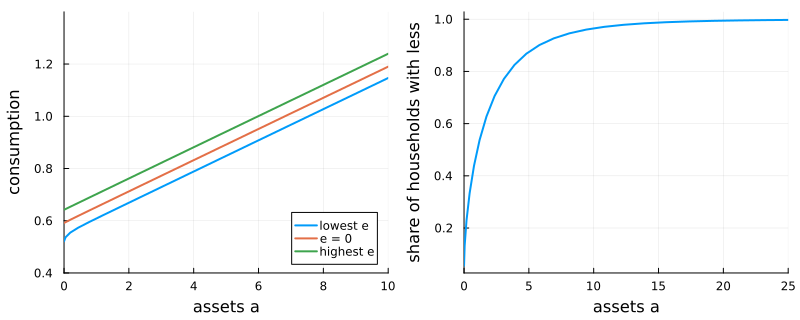

In [ ]:
agg3, gri3 = reiter3.agg, reiter3.gri
pa = plot(xlabel = "assets a", ylabel = "consumption", xlims = (0, 10), ylims = (0.4, 1.4), legend = :bottomright)
for (m, label) in ((1, "lowest e"), (3, "e = 0"), (5, "highest e"))
    plot!(pa, gri3.a, agg3.c[:, m], lw = 2, label = label)
end
pb = plot(gri3.a, cumsum(vec(sum(agg3.lam, dims = 2))), lw = 2, label = "", xlabel = "assets a", ylabel = "share of households with less",
          xlims = (0, 25))
plot(pa, pb, layout = (1, 2), size = (800, 320), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)

**3.3 (a):** Impulse responses of CRRA-Reiter and the representative agent.

#### Question 3.3: The dynamics

                                     C on impact   K at peak  period
CRRA, Reiter                               0.544       1.044      11
CRRA, representative agent                 0.545       1.051      11


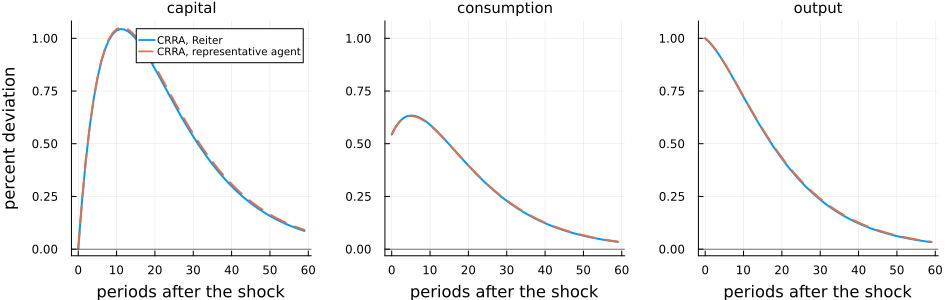

In [ ]:
compare(["CRRA, Reiter" => reiter3, "CRRA, representative agent" => rbc3])
plot_irfs(["CRRA, Reiter" => reiter3, "CRRA, representative agent" => rbc3])

**3.3 (b):** Compare the impulse responses.

In [ ]:
@printf("maximum absolute CRRA–RBC gap (percentage points):\n")
for (name, h, p) in (("capital", reiter3.K, rbc3.K), ("consumption", reiter3.C, rbc3.C),
                     ("output", reiter3.Y, rbc3.Y))
    @printf("  %-12s %.6f\n", name, 100 * maximum(abs.(h .- p)))
end

maximum absolute CRRA–RBC gap (percentage points):
  capital      0.013443
  consumption  0.003013
  output       0.004839


The aggregate impulse responses are very close, although not identical. Indeed, despite the CRRA economy featuring heterogeneous wealth, precautionary saving and households at the borrowing constraint, whereas the representative agent does not, differences in individual household responses largely cancel out or have limited effects in the aggregate. 

#### Question 3.4: Income risk

**3.4 (a):** For each income-risk level, recalibrate $\beta$, tabulate the borrowing-limit share, and plot the three CRRA impulse responses alongside the representative agent.

Reiter (CRRA) with EconomicParameters(0.36, 0.1, 3.0, 0.9777777777777777, 0.9, 0.0, 0.9, 0.974710088528268, 0.7117659246173289), N_a = 80, N_e = 5, grid = [0.0, 300.0]
  steady state: r* = 4.00000 percent, K = 2.57143, C = 0.74286, mass at a_1: 2.3e-02, at a_N: 1.5e-07, households with a' = a_1: 0.00 percent (0.3 s)
  Reiter: 801 variables, largest residual at the steady state 1.2e-09, 401 stable eigenvalues for 401 states, Jacobians 1.2 s, Klein 1.5 s
  C on impact 0.537 percent, K peaks at 1.056 percent in period 11, goods market gap 9.4e-08
Reiter (CRRA) with EconomicParameters(0.36, 0.1, 3.0, 0.9777777777777777, 0.9, 0.3, 0.9, 0.9605573069863431, 0.7117659246173289), N_a = 80, N_e = 5, grid = [0.0, 300.0]
  steady state: r* = 4.00000 percent, K = 2.57143, C = 0.74286, mass at a_1: 1.2e-01, at a_N: 5.3e-34, households with a' = a_1: 9.27 percent (0.2 s)
  Reiter: 801 variables, largest residual at the steady state 7.9e-10, 401 stable eigenvalues for 401 states, Jacobians 1.0 s, Klei

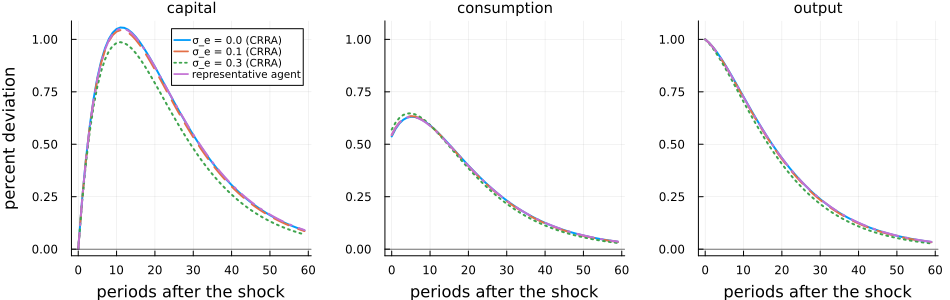

In [31]:
# 3.4 (a): income-risk experiments, with separate β calibrations
par3_no_risk = calibrate_beta(change(par3; σ_e = 0.0), mpar3, CRRA)
par3_high_risk = calibrate_beta(change(par3; σ_e = 0.3), mpar3, CRRA)
reiter3_no_risk = solve_reiter(par3_no_risk, mpar3, CRRA)
reiter3_high_risk = solve_reiter(par3_high_risk, mpar3, CRRA)
crra_risk = Dict{Float64,Any}(0.0 => reiter3_no_risk, 0.1 => reiter3, 0.3 => reiter3_high_risk)
@printf("%-8s %13s %20s\n", "σ_e", "β", "a′ = 0 (%)")
for risk in (0.0, 0.1, 0.3)
    rr = crra_risk[risk]
    @printf("%-8.1f %13.8f %20.4f\n", risk, rr.par.β, 100 * rr.at_limit)
end
display(plot_irfs(["σ_e = 0.0 (CRRA)" => reiter3_no_risk,
                   "σ_e = 0.1 (CRRA)" => reiter3,
                   "σ_e = 0.3 (CRRA)" => reiter3_high_risk,
                   "representative agent" => rbc3]))

**3.4 (b):** In which of the three economies do the aggregates differ most from the representative agent, and why?

In [ ]:
risk_gaps = Dict{Float64,Float64}()
@printf("%-8s %13s %13s %13s %13s\n", "σ_e", "K gap (pp)", "C gap (pp)", "Y gap (pp)", "max (pp)")
for risk in (0.0, 0.1, 0.3)
    rr = crra_risk[risk]
    gaps = [100 * maximum(abs.(getproperty(rr, key) .- getproperty(rbc3, key))) for key in (:K, :C, :Y)]
    risk_gaps[risk] = maximum(gaps)
    @printf("%-8.1f %13.6f %13.6f %13.6f %13.6f\n", risk, gaps..., risk_gaps[risk])
end
worst_risk = first(sort(collect(keys(risk_gaps)); by = risk -> (-risk_gaps[risk], risk)))
@printf("largest aggregate deviation from RBC: σ_e = %.1f (maximum %.6f percentage points)\n",
        worst_risk, risk_gaps[worst_risk])

σ_e         K gap (pp)    C gap (pp)    Y gap (pp)      max (pp)
0.0           0.006445      0.007501      0.002320      0.007501
0.1           0.013443      0.003013      0.004839      0.013443
0.3           0.077636      0.025361      0.027949      0.077636
largest aggregate deviation from RBC: σ_e = 0.3 (maximum 0.077636 percentage points)


Across the different specifications, the economy with the highest income risk (sigma_e=0.3) exhibits the largest differences from the representative-agent economy, with a maximum absolute gap of 0.078 percentage points. This can be explained by stronger precautionary-saving incentives and a higher share of borrowing-constrained households as income risk increases. These mechanisms affect households' saving and consumption responses to the productivity shock, leading to greater deviations in aggregate dynamics from the RBC benchmark.

**3.4 (c):** Even with $\sigma_e=0$, households have different assets and consumption because households enter the economy at different times, and while surviving households have accumulated savings, newborns begin with $a=0$. Thus, demographic turnover implies heterogeneity in wealth, so this is not a representative-agent economy.